# 02 — Mathematical Foundations of Neural Networks
### The mathematics behind the computations

**Learning path:** Deep Learning / Keras · **Notebook:** 02 of 12  
**Tools:** Python, NumPy, Matplotlib  
**Context:** Small biological-style numerical examples

## Learning objectives

By the end, you should be able to:
1. Distinguish scalars, vectors, matrices, and tensors.
2. Interpret the shapes of data and neural-network parameters.
3. Compute dot products, matrix products, and affine transformations.
4. Explain activation and loss functions.
5. Understand derivatives, partial derivatives, and the chain rule.
6. Explain gradient descent and backpropagation.
7. Implement a small neural network using NumPy, without a deep-learning framework.

> No PyTorch or Keras knowledge is required. This notebook develops the mathematical foundations needed for later Keras examples.

## 1. Why Mathematics Matters

A neural network is a parameterized mathematical function:

$$
\hat{y} = f(x; \theta)
$$

Here, $x$ represents the input, $\hat{y}$ is the model's prediction, and $\theta$ represents the learnable parameters, typically weights and biases. During training, the model adjusts these parameters to minimize a chosen objective function.

The main mathematical foundations of neural networks are:

- **Linear Algebra:** Represents data, weights, and mathematical transformations using vectors and matrices.
- **Calculus:** Explains how outputs and loss values change with respect to model parameters.
- **Probability and Statistics:** Provide the foundations for sampling, interpreting predictions, and evaluating model performance.
- **Optimization:** Provides algorithms for updating parameters to minimize the objective function.

The goal is not simply to memorize formulas. It is to understand what the model computes, how its components interact, and why the learning process works.

## 2. Scalars, vectors, matrices, and tensors

A **scalar** is one number. A **vector** is an ordered one-dimensional collection. A **matrix** is a two-dimensional array. A **tensor** generalizes arrays to any number of dimensions.

| Object | Rank (number of axes) | Example shape |
|---|---:|---|
| Scalar | 0 | `()` |
| Vector | 1 | `(5,)` |
| Matrix | 2 | `(3, 5)` |
| 3D tensor | 3 | `(samples, time, features)` |
| Image batch | 4 | `(batch, height, width, channels)` |

Rank is the number of axes, not the number of elements. Shape is part of the data's meaning.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

scalar = np.array(3.14)
vector = np.array([1.2, 0.7, 2.4, 1.8])
matrix = np.array([[1.0, 0.2, 0.4], [0.3, 1.5, 0.8]])
tensor_3d = np.zeros((4, 10, 3))

for name, value in [("scalar", scalar), ("vector", vector),
                    ("matrix", matrix), ("tensor_3d", tensor_3d)]:
    print(f"{name:12} shape={value.shape!s:12} rank={value.ndim} size={value.size}")

scalar       shape=()           rank=0 size=1
vector       shape=(4,)         rank=1 size=4
matrix       shape=(2, 3)       rank=2 size=6
tensor_3d    shape=(4, 10, 3)   rank=3 size=120


### 2.1 A Biological-Style Feature Matrix

Imagine a gene-expression dataset containing 120 biological samples and measurements for 500 genes:

$$
X \in \mathbb{R}^{120 \times 500}
$$

Here:

- **Rows (120):** Represent individual biological samples.
- **Columns (500):** Represent measured gene-expression features.
- **Each row:** Contains 500 gene-expression values for one sample.
- **Each column:** Contains the expression measurements of one gene across all 120 samples.

Therefore, a single sample can be represented as a 500-dimensional feature vector:

$$
x_i \in \mathbb{R}^{500}
$$

In real-world biological studies, the meaning of each sample, feature, and associated label must be clearly documented. This includes measurement units, preprocessing methods, missing values, and sample identifiers.

In [2]:
expression = np.array([
    [2.1, 0.4, 1.7, 3.0, 0.8],
    [1.8, 0.6, 1.2, 2.7, 1.1],
    [0.5, 2.4, 0.7, 1.0, 2.8],
    [0.7, 2.1, 0.9, 1.2, 2.5],
])
print("Dataset shape:", expression.shape)
print("Samples:", expression.shape[0], "| Features:", expression.shape[1])
print("First sample:", expression[0])
print("Third feature across samples:", expression[:, 2])

Dataset shape: (4, 5)
Samples: 4 | Features: 5
First sample: [2.1 0.4 1.7 3.  0.8]
Third feature across samples: [1.7 1.2 0.7 0.9]


## 3. Linear Algebra in a Dense Layer

A fully connected (Dense) layer applies an affine transformation to its input:

$$
Z = XW + b
$$

For a batch of $N$ samples, $F$ input features, and $U$ output units, the dimensions are:

$$
\underbrace{(N \times F)}_{X}
\underbrace{(F \times U)}_{W}
+
\underbrace{(U,)}_{b}
\longrightarrow
\underbrace{(N \times U)}_{Z}
$$

Where:

- $X$ is the input matrix.
- $W$ is the weight matrix.
- $b$ is the bias vector.
- $Z$ is the resulting output matrix before applying an activation function.

The bias vector is broadcast across all $N$ samples, meaning the same bias values are added to each row of the result.

### Example

Suppose a batch contains 120 samples, each represented by 500 features, and the Dense layer has 64 output units:

$$
X \in \mathbb{R}^{120 \times 500}
$$

$$
W \in \mathbb{R}^{500 \times 64}
$$

$$
b \in \mathbb{R}^{64}
$$

The resulting output has the shape:

$$
Z \in \mathbb{R}^{120 \times 64}
$$

Each sample is therefore transformed from a 500-dimensional feature vector into a 64-dimensional representation.

Some textbooks use column vectors and write $Wx+b$ instead of $XW+b$. Both conventions are mathematically valid. The important point is to remain consistent with the chosen convention and track matrix dimensions carefully.

### Matrix Multiplication Rule

For two matrices:

$$
A \in \mathbb{R}^{m \times n}
$$

$$
B \in \mathbb{R}^{n \times p}
$$

Their product is defined as:

$$
AB \in \mathbb{R}^{m \times p}
$$

The inner dimensions must match. The resulting matrix takes its row count from the first matrix and its column count from the second.

In [3]:
A = np.array([[1, 2, 3], [4, 5, 6]], dtype=float)  # (2, 3)
B = np.array([[1, 0], [0, 1], [1, 1]], dtype=float)  # (3, 2)
print("A @ B shape:", (A @ B).shape)
print(A @ B)

C = np.array([[2, 3, 4], [5, 6, 7]], dtype=float)
print("Element-wise A * C:")
print(A * C)

A @ B shape: (2, 2)
[[ 4.  5.]
 [10. 11.]]
Element-wise A * C:
[[ 2.  6. 12.]
 [20. 30. 42.]]


### 3.1 Dot Product and Weighted Sum

For two vectors of equal length, the dot product is defined as:

$$
x \cdot w = \sum_{i=1}^{n} x_i w_i
$$

A neuron combines this weighted sum with a bias:

$$
z = x \cdot w + b
$$

Expanding the equation:

$$
z = x_1w_1 + x_2w_2 + \cdots + x_nw_n + b
$$

Each input feature is multiplied by its corresponding weight. The resulting values are summed, and the bias is added.

### Numerical Example

Consider a neuron with three input features:

$$
x = [2, 3, 1]
$$

and corresponding weights:

$$
w = [0.5, -1, 2]
$$

Let the bias be:

$$
b = 1
$$

The weighted sum is:

$$
z = (2 \times 0.5) + (3 \times -1) + (1 \times 2) + 1
$$

$$
z = 1 - 3 + 2 + 1 = 1
$$

The final result before applying an activation function is $z=1$.

The dot product allows a neuron to combine multiple input features into a single weighted value. During training, the model learns the weights and bias to produce useful representations and predictions.

In [4]:
x = np.array([2.0, 0.5, 1.5])
w = np.array([0.3, -0.2, 0.8])
b = 0.1

manual_dot = sum(x[i] * w[i] for i in range(len(x)))
numpy_dot = np.dot(x, w)
print("Manual dot:", manual_dot)
print("NumPy dot:", numpy_dot)
print("Pre-activation z:", numpy_dot + b)

Manual dot: 1.7000000000000002
NumPy dot: 1.7000000000000002
Pre-activation z: 1.8000000000000003


In [5]:
# A batch: 3 samples, 3 features, 2 output units.
X_demo = np.array([[2.0, 0.5, 1.5], [1.0, 1.0, 0.0], [0.2, 0.7, 2.0]])
W_demo = np.array([[0.3, -0.1], [-0.2, 0.4], [0.8, 0.2]])
b_demo = np.array([0.1, -0.05])
Z_demo = X_demo @ W_demo + b_demo
print("X:", X_demo.shape, "W:", W_demo.shape, "b:", b_demo.shape)
print("Z:", Z_demo.shape)
print(Z_demo)

X: (3, 3) W: (3, 2) b: (2,)
Z: (3, 2)
[[1.8  0.25]
 [0.2  0.25]
 [1.62 0.61]]


## 4. Linear and Affine Transformations

A **linear transformation** preserves vector addition and scalar multiplication. Matrix multiplication is a common way to represent a linear transformation.

Adding a bias term makes the operation an **affine transformation**:

$$
f(x) = xW + b
$$

Unlike a purely linear transformation, an affine transformation does not necessarily map the zero vector to the zero vector.

### Why Nonlinearity Matters

Consider two affine layers without nonlinear activation functions:

$$
h = xW_1 + b_1
$$

$$
y = hW_2 + b_2
$$

Substituting the first equation into the second:

$$
y = (xW_1+b_1)W_2+b_2
$$

Expanding:

$$
y = x(W_1W_2)+(b_1W_2+b_2)
$$

This is still an affine transformation. Therefore, two consecutive affine layers without nonlinear activations can be represented as a single affine layer.

The same principle applies to any finite number of affine layers.

### The Role of Activation Functions

Nonlinear activation functions allow neural networks to learn more complex relationships than a single affine transformation.

For example, applying ReLU between two layers:

$$
h = \operatorname{ReLU}(xW_1+b_1)
$$

$$
y = hW_2+b_2
$$

introduces nonlinearity into the network.

This is essential for learning complex patterns in data, such as gene-expression relationships, image structures, and biological classification tasks.

**Key takeaway:** Depth alone does not make a neural network more expressive. Nonlinear activation functions enable stacked layers to learn complex nonlinear mappings.

## 5. Activation Functions

An activation function transforms a neuron's pre-activation value $z$ into an output $a$:

$$
a = \phi(z)
$$

Activation functions introduce nonlinearity into neural networks, allowing them to learn complex patterns and relationships.

### 5.1 ReLU (Rectified Linear Unit)

$$
\operatorname{ReLU}(z)=\max(0,z)
$$

- Returns zero for negative inputs.
- Returns the input itself for positive values.
- Commonly used in hidden layers.
- Computationally efficient and helps reduce the vanishing gradient problem compared with sigmoid and tanh in many settings.

### 5.2 Sigmoid

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

- Maps real-valued inputs to the interval $(0,1)$.
- Commonly used in the output layer of binary classification models.
- Its output can be interpreted as a predicted probability when the model is appropriately trained and calibrated.
- Can suffer from vanishing gradients for very large positive or negative inputs.

### 5.3 Tanh (Hyperbolic Tangent)

$$
\tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}
$$

- Maps real-valued inputs to the interval $(-1,1)$.
- Produces zero-centered outputs.
- Historically used in hidden layers and recurrent neural networks.
- Can also suffer from vanishing gradients when inputs have large magnitudes.

### 5.4 Softmax

For a vector of logits $z$, Softmax is defined as:

$$
\operatorname{softmax}(z_i)=
\frac{e^{z_i}}{\sum_j e^{z_j}}
$$

- Converts logits into non-negative values that sum to one.
- Commonly used for mutually exclusive multiclass classification.
- Each output represents a predicted class probability under the model's categorical distribution.

For numerical stability, implementations commonly subtract the maximum logit before exponentiation:

$$
\operatorname{softmax}(z_i)=
\frac{e^{z_i-\max(z)}}{\sum_j e^{z_j-\max(z)}}
$$

### Choosing an Activation Function

| Function | Output range | Common application |
|---|---|---|
| ReLU | $[0,\infty)$ | Hidden layers |
| Sigmoid | $(0,1)$ | Binary classification |
| Tanh | $(-1,1)$ | Hidden layers, some recurrent networks |
| Softmax | $(0,1)$, sum = 1 | Multiclass classification |

**Key takeaway:** The choice of activation function depends on the network architecture and the prediction task. Hidden layers commonly use ReLU, while output layers often use sigmoid for binary classification and softmax for mutually exclusive multiclass classification.

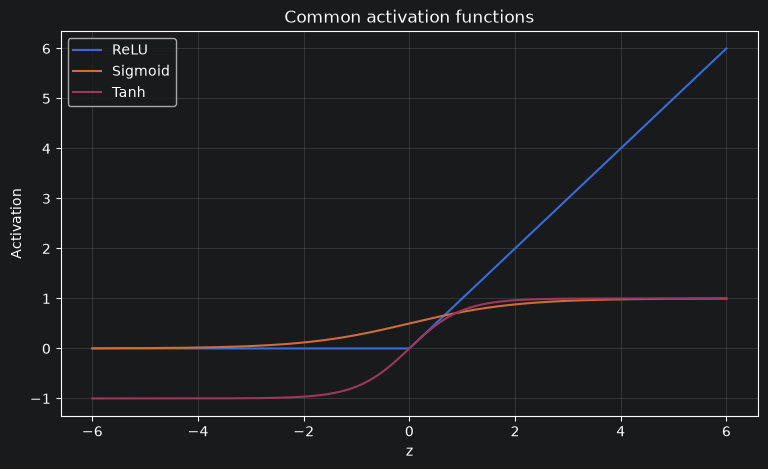

Logits: [ 1.2  0.3 -0.4]
Softmax: [0.6217 0.2528 0.1255]


In [6]:
def relu(z):
    return np.maximum(0, z)

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def softmax(z):
    shifted = z - np.max(z, axis=-1, keepdims=True)
    e = np.exp(shifted)
    return e / e.sum(axis=-1, keepdims=True)

z_values = np.linspace(-6, 6, 300)
plt.figure(figsize=(9, 5))
plt.plot(z_values, relu(z_values), label="ReLU")
plt.plot(z_values, sigmoid(z_values), label="Sigmoid")
plt.plot(z_values, np.tanh(z_values), label="Tanh")
plt.xlabel("z"); plt.ylabel("Activation")
plt.title("Common activation functions")
plt.legend(); plt.grid(alpha=0.25); plt.show()

logits = np.array([1.2, 0.3, -0.4])
print("Logits:", logits)
print("Softmax:", np.round(softmax(logits), 4))

### 5.1 Choosing an activation

| Problem / location | Common choice | Reason |
|---|---|---|
| Hidden layers | ReLU | Simple nonlinear activation |
| Binary output | Sigmoid | One score in (0, 1) |
| Mutually exclusive multiclass output | Softmax | Normalized class distribution |
| Regression output | Often linear | Allows a continuous range |

These are common patterns, not rigid laws. Multilabel classification often uses independent sigmoid outputs rather than one softmax. The output activation, target encoding, and loss must be compatible.

## 6. Loss Functions

A loss function measures the difference between a model's predictions and the actual target values. It converts prediction errors into a numerical objective that the training algorithm attempts to minimize.

The choice of loss function depends on the prediction task and the format of the target labels.

### 6.1 Mean Squared Error (MSE)

$$
\operatorname{MSE}=\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2
$$

- Calculates the average squared difference between actual and predicted values.
- Penalizes large errors more heavily because residuals are squared.
- Commonly used in regression tasks.
- Can be sensitive to outliers.

Here, $y_i$ is the actual value, $\hat{y}_i$ is the predicted value, and $N$ is the number of samples.

### 6.2 Mean Absolute Error (MAE)

$$
\operatorname{MAE}=\frac{1}{N}\sum_{i=1}^{N}|y_i-\hat{y}_i|
$$

- Calculates the average absolute difference between actual and predicted values.
- Penalizes errors linearly.
- Is generally less sensitive to large residuals than MSE.
- Commonly used in regression tasks.

### 6.3 Binary Cross-Entropy (BCE)

$$
L=-\frac{1}{N}\sum_{i=1}^{N}
\left[
y_i\log(p_i)+(1-y_i)\log(1-p_i)
\right]
$$

- Commonly used for binary classification.
- Assumes binary targets, typically encoded as 0 and 1.
- $p_i$ represents the predicted probability of the positive class.
- Often paired with a sigmoid output layer.

### 6.4 Categorical Cross-Entropy (CCE)

$$
L=-\frac{1}{N}\sum_{i=1}^{N}\sum_{k=1}^{K}
y_{ik}\log(p_{ik})
$$

- Commonly used for mutually exclusive multiclass classification.
- Typically uses one-hot encoded target labels.
- $K$ represents the number of classes.
- Often paired with a softmax output layer.

**Sparse Categorical Cross-Entropy** uses integer class labels instead of one-hot encoded target vectors. It is useful when each sample belongs to exactly one class.

### 6.5 Comparing Loss Functions

| Loss function | Task | Typical output |
|---|---|---|
| MSE | Regression | Linear |
| MAE | Regression | Linear |
| Binary Cross-Entropy | Binary classification | Sigmoid |
| Categorical Cross-Entropy | Multiclass classification | Softmax |
| Sparse Categorical Cross-Entropy | Multiclass classification | Softmax |

### Important Implementation Note

Modern deep learning frameworks use numerically stable implementations of loss functions. Some implementations can accept logits directly, avoiding the need to manually apply sigmoid or softmax before calculating the loss.

For example, TensorFlow/Keras provides loss configurations that combine the output activation and loss calculation in a numerically stable way.

**Key takeaway:** A loss function defines what the model is trying to minimize. Choosing the appropriate loss is essential for matching the model's training objective to the prediction task.

In [7]:
y_true_reg = np.array([2.0, 1.0, 4.0, 3.0])
y_pred_reg = np.array([2.5, 0.5, 3.0, 4.0])
print("MSE:", np.mean((y_true_reg - y_pred_reg) ** 2))
print("MAE:", np.mean(np.abs(y_true_reg - y_pred_reg)))

def binary_crossentropy(y_true, y_prob, eps=1e-7):
    p = np.clip(y_prob, eps, 1 - eps)
    return -np.mean(y_true*np.log(p) + (1-y_true)*np.log(1-p))

y_bin = np.array([1, 0, 1, 1], dtype=float)
print("BCE good:", binary_crossentropy(y_bin, np.array([.9, .1, .8, .7])))
print("BCE poor:", binary_crossentropy(y_bin, np.array([.4, .6, .3, .2])))

MSE: 0.625
MAE: 0.75
BCE good: 0.19763488164214868
BCE poor: 1.1614980451270867


In [8]:
def categorical_crossentropy(y_onehot, probabilities, eps=1e-7):
    p = np.clip(probabilities, eps, 1 - eps)
    return -np.mean(np.sum(y_onehot * np.log(p), axis=1))

y_onehot = np.eye(3)
p_good = np.array([[.8,.1,.1], [.2,.7,.1], [.05,.15,.8]])
print("Categorical cross-entropy:", categorical_crossentropy(y_onehot, p_good))

Categorical cross-entropy: 0.26765401552238394


### 6.1 Loss versus metric

Loss is the objective optimized during training. Metrics are reported to help assess model behavior. They are not necessarily interchangeable.

In imbalanced biomedical classification, accuracy alone may be misleading. Precision, recall, F1-score, sensitivity, specificity, ROC-AUC, or precision-recall analysis may be more informative depending on the research question. Choose evaluation criteria based on the intended use, not after seeing the final test results.

## 7. Derivatives and Partial Derivatives

A derivative describes how a function changes with respect to a small change in its input. It measures the rate of change of a function at a particular point.

For a function $f(x)$, the derivative is defined as:

$$
\frac{df}{dx}
=
\lim_{h\to0}
\frac{f(x+h)-f(x)}{h}
$$

### 7.1 Understanding a Derivative

Consider the function:

$$
f(x)=x^2
$$

Its derivative is:

$$
\frac{df}{dx}=2x
$$

At $x=3$, the derivative is:

$$
f'(3)=2(3)=6
$$

This means that near $x=3$, a small change in $x$ produces an approximately six-times-larger change in the function's output.

### 7.2 Partial Derivatives

When a function depends on multiple variables, a partial derivative measures how the function changes with respect to one variable while keeping the other variables fixed.

For example, consider:

$$
f(w,b)=w^2+3b
$$

The partial derivatives are:

$$
\frac{\partial f}{\partial w}=2w
$$

$$
\frac{\partial f}{\partial b}=3
$$

The first derivative measures sensitivity to changes in $w$, while the second measures sensitivity to changes in $b$.

### 7.3 Why Derivatives Matter in Neural Networks

A neural network contains many learnable parameters, including weights and biases. During training, we need to understand how changing these parameters affects the loss function.

For a loss function $L$, the relevant derivatives include:

$$
\frac{\partial L}{\partial w}
\qquad
\frac{\partial L}{\partial b}
$$

These derivatives indicate how sensitive the loss is to changes in individual parameters.

They provide the mathematical foundation for gradient-based optimization algorithms, which update model parameters to reduce the loss.

**Key takeaway:** Derivatives measure rates of change, while partial derivatives measure how a function changes with respect to individual variables. Both are essential for understanding how neural networks learn.

In [9]:
def f(x):
    return x**2

x0, h = 3.0, 1e-5
numerical = (f(x0+h) - f(x0-h)) / (2*h)
analytical = 2*x0
print("Numerical derivative:", numerical)
print("Analytical derivative:", analytical)

Numerical derivative: 6.000000000039306
Analytical derivative: 6.0


## 8. The Chain Rule and Computational Graphs

Neural networks are built by composing multiple mathematical functions. The **chain rule** allows us to calculate derivatives through these compositions.

If:

$$
y=f(u), \qquad u=g(x)
$$

then the derivative of $y$ with respect to $x$ is:

$$
\frac{dy}{dx}
=
\frac{df}{du}
\frac{du}{dx}
$$

This means that the total effect of changing $x$ on $y$ can be calculated by multiplying the local derivatives along the computational path.

### 8.1 The Chain Rule in a Neuron

Consider a neuron with the following operations:

$$
z=wx+b
$$

$$
a=\sigma(z)
$$

where $\sigma$ is the sigmoid activation function.

Suppose the loss is defined as $L(a,y)$, where $y$ is the true target.

To calculate how the loss changes with respect to the weight $w$, we apply the chain rule:

$$
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial a}
\frac{\partial a}{\partial z}
\frac{\partial z}{\partial w}
$$

Each derivative represents a local contribution:

- $\frac{\partial L}{\partial a}$ measures how the loss changes with the neuron's output.
- $\frac{\partial a}{\partial z}$ measures how the activation output changes with its input.
- $\frac{\partial z}{\partial w}$ measures how the pre-activation value changes with the weight.

Similarly, the derivative with respect to the bias is:

$$
\frac{\partial L}{\partial b}
=
\frac{\partial L}{\partial a}
\frac{\partial a}{\partial z}
\frac{\partial z}{\partial b}
$$

### 8.2 Computational Graphs

A computational graph represents a mathematical calculation as a sequence of operations connected by dependencies.

For the neuron above, the computational flow is:

$$
(x,w,b)\rightarrow z\rightarrow a\rightarrow L
$$

Each operation contributes a local derivative that is used to calculate gradients during the backward pass.

### 8.3 Connection to Backpropagation

**Backpropagation** applies the chain rule repeatedly, propagating gradients backward through the computational graph.

Starting from the loss, the algorithm calculates how each parameter contributes to the final prediction error.

These gradients are then used by an optimization algorithm, such as gradient descent or Adam, to update the model parameters.

**Key takeaway:** The chain rule explains how gradients flow through a neural network. Backpropagation is the systematic application of this rule to calculate gradients for all learnable parameters.

## 9. Gradient Descent

Gradient descent is an optimization algorithm used to minimize a loss function by iteratively updating model parameters.

Let the model parameters be represented by $\theta$, and let the loss function be $L(\theta)$. The gradient descent update rule is:

$$
\theta_{\mathrm{new}}
=
\theta_{\mathrm{old}}
-
\eta\nabla_\theta L
$$

Where:

- $\theta$ represents the model parameters, including weights and biases.
- $\nabla_\theta L$ is the gradient of the loss with respect to those parameters.
- $\eta$ is the learning rate, which controls the size of each update.

The gradient points in the direction of the steepest local increase in the loss. Gradient descent moves in the opposite direction to reduce the objective.

### 9.1 Understanding the Learning Rate

The learning rate determines how much the parameters change during each update.

- **Too small:** Training may progress very slowly.
- **Too large:** Updates may overshoot a minimum or become unstable.
- **Appropriate:** Updates can make steady progress toward a minimum.

The best learning rate depends on the dataset, model architecture, parameterization, and optimization algorithm.

### 9.2 A Numerical Example

Consider a simple loss function:

$$
L(\theta)=\theta^2
$$

Its derivative is:

$$
\frac{dL}{d\theta}=2\theta
$$

Suppose the initial parameter is $\theta=4$ and the learning rate is $\eta=0.1$.

The first update becomes:

$$
\theta_{\mathrm{new}}=4-0.1(2\times4)
$$

$$
\theta_{\mathrm{new}}=3.2
$$

The parameter moves closer to the minimum at $\theta=0$, reducing the loss from $16$ to $10.24$.

### 9.3 Types of Gradient Descent

- **Batch Gradient Descent:** Calculates gradients using the entire training dataset before each update.
- **Stochastic Gradient Descent (SGD):** Updates parameters using one training sample at a time.
- **Mini-batch Gradient Descent:** Calculates gradients using a small subset of training samples. This is commonly used in deep learning.

### 9.4 Adaptive Optimization Algorithms

Some optimizers adjust parameter update scales using information from previous gradients.

Examples include:

- **SGD:** Uses the gradient to update parameters, optionally with momentum.
- **RMSprop:** Adapts update scales using a moving average of squared gradients.
- **Adam:** Combines momentum-like first-moment estimates with adaptive second-moment estimates.

**Key takeaway:** Gradient descent provides the fundamental mechanism for reducing a neural network's loss. The learning rate and optimization algorithm influence how effectively the model learns.

Final parameter: 3.9926
Final loss: 5.5e-05


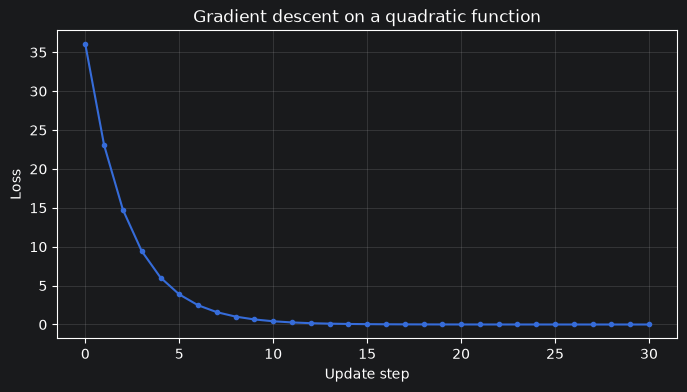

In [10]:
# Minimize f(w) = (w - 4)^2 using gradient descent.
w = -2.0
learning_rate = 0.1
loss_history = [(w - 4)**2]

for step in range(30):
    gradient = 2 * (w - 4)
    w -= learning_rate * gradient
    loss_history.append((w - 4)**2)

print("Final parameter:", round(w, 4))
print("Final loss:", round(loss_history[-1], 6))
plt.figure(figsize=(8, 4))
plt.plot(loss_history, marker="o", markersize=3)
plt.xlabel("Update step"); plt.ylabel("Loss")
plt.title("Gradient descent on a quadratic function")
plt.grid(alpha=0.25); plt.show()

## 10. Backpropagation: A Single-Neuron Example

Consider a single linear neuron with one input and one observation:

$$
\hat{y}=wx+b
$$

The prediction error is measured using the squared error loss:

$$
L=\frac{1}{2}(\hat{y}-y)^2
$$

Here, $x$ is the input, $y$ is the true target, $\hat{y}$ is the prediction, and $w$ and $b$ are the learnable weight and bias.

The factor $\frac{1}{2}$ is included to simplify the derivatives.

### 10.1 Calculating the Gradients

Using the chain rule, the derivative of the loss with respect to the weight is:

$$
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial \hat{y}}
\frac{\partial \hat{y}}{\partial w}
$$

Since:

$$
\frac{\partial L}{\partial \hat{y}}=\hat{y}-y
$$

and:

$$
\frac{\partial \hat{y}}{\partial w}=x
$$

we obtain:

$$
\boxed{
\frac{\partial L}{\partial w}=(\hat{y}-y)x
}
$$

Similarly, the derivative with respect to the bias is:

$$
\frac{\partial L}{\partial b}
=
\frac{\partial L}{\partial \hat{y}}
\frac{\partial \hat{y}}{\partial b}
$$

Therefore:

$$
\boxed{
\frac{\partial L}{\partial b}=(\hat{y}-y)
}
$$

### 10.2 Updating the Parameters

Once the gradients have been calculated, gradient descent updates the weight and bias:

$$
w_{\mathrm{new}}
=
w_{\mathrm{old}}
-
\eta\frac{\partial L}{\partial w}
$$

$$
b_{\mathrm{new}}
=
b_{\mathrm{old}}
-
\eta\frac{\partial L}{\partial b}
$$

Here, $\eta$ is the learning rate.

### 10.3 Interpretation

The gradients indicate how sensitive the loss is to changes in the weight and bias.

- A positive gradient means increasing the corresponding parameter locally increases the loss.
- A negative gradient means increasing the parameter locally decreases the loss.
- A gradient close to zero indicates that the loss changes very little for a small parameter adjustment.

This example demonstrates the basic principle of backpropagation: calculate gradients using the chain rule, then use an optimizer to update the learnable parameters.

**Key takeaway:** Even a single neuron can learn by calculating how its weight and bias contribute to prediction error and adjusting them to reduce the loss.

In [11]:
x, y, w, b = 2.0, 5.0, 0.5, 0.0
y_hat = w*x + b
loss = 0.5*(y_hat-y)**2
grad_w = (y_hat-y)*x
grad_b = (y_hat-y)
print("Prediction:", y_hat, "Loss:", loss)
print("dL/dw:", grad_w, "dL/db:", grad_b)

def neuron_loss(wv, bv):
    return 0.5 * (wv*x + bv - y)**2

eps = 1e-5
num_dw = (neuron_loss(w+eps,b)-neuron_loss(w-eps,b))/(2*eps)
num_db = (neuron_loss(w,b+eps)-neuron_loss(w,b-eps))/(2*eps)
print("Numerical gradients:", num_dw, num_db)

Prediction: 1.0 Loss: 8.0
dL/dw: -8.0 dL/db: -4.0
Numerical gradients: -8.00000000005241 -3.9999999998929776


In [12]:
lr = 0.05
w_new = w - lr*grad_w
b_new = b - lr*grad_b
print("Before:", {"w": w, "b": b, "prediction": w*x+b})
print("After: ", {"w": w_new, "b": b_new, "prediction": w_new*x+b_new})

Before: {'w': 0.5, 'b': 0.0, 'prediction': 1.0}
After:  {'w': 0.9, 'b': 0.2, 'prediction': 2.0}


## 11. A Tiny Neural Network from Scratch with NumPy

We now combine the mathematical concepts into a two-layer neural network for binary classification.

The network consists of an input layer, one hidden layer with ReLU activation, and an output layer with sigmoid activation.

### 11.1 Network Architecture

The forward pass is defined as:

$$
Z_1=XW_1+b_1
$$

$$
A_1=\operatorname{ReLU}(Z_1)
$$

$$
Z_2=A_1W_2+b_2
$$

$$
\hat{y}=\sigma(Z_2)
$$

Here, $\hat{y}$ represents the predicted probability of the positive class.

### 11.2 Understanding the Shapes

Assume the dataset contains $N$ samples, $F$ input features, and $H$ hidden units.

| Variable | Shape | Description |
|---|---|---|
| $X$ | $(N,F)$ | Input features |
| $W_1$ | $(F,H)$ | First-layer weights |
| $b_1$ | $(1,H)$ | First-layer bias |
| $Z_1$ | $(N,H)$ | Hidden-layer linear output |
| $A_1$ | $(N,H)$ | Hidden-layer activations |
| $W_2$ | $(H,1)$ | Output-layer weights |
| $b_2$ | $(1,1)$ | Output-layer bias |
| $Z_2$ | $(N,1)$ | Output logits |
| $\hat{y}$ | $(N,1)$ | Predicted probabilities |

Bias vectors are broadcast across the samples during matrix addition.

### 11.3 Loss Function

For binary classification, we use Binary Cross-Entropy (BCE):

$$
L=-\frac{1}{N}\sum_{i=1}^{N}
\left[
y_i\log(\hat{y}_i)
+(1-y_i)\log(1-\hat{y}_i)
\right]
$$

The objective is to minimize this loss by adjusting the network's weights and biases.

### 11.4 Backpropagation

The gradients are calculated using the chain rule.

For the output layer:

$$
dZ_2=\frac{\hat{y}-y}{N}
$$

$$
dW_2=A_1^T dZ_2
$$

$$
db_2=\sum_{i=1}^{N}dZ_{2,i}
$$

For the hidden layer:

$$
dA_1=dZ_2W_2^T
$$

$$
dZ_1=dA_1\odot\operatorname{ReLU}'(Z_1)
$$

where $\odot$ denotes element-wise multiplication and:

$$
\operatorname{ReLU}'(z)=
\begin{cases}
1 & z>0\\
0 & z\leq 0
\end{cases}
$$

The remaining gradients are:

$$
dW_1=X^TdZ_1
$$

$$
db_1=\sum_{i=1}^{N}dZ_{1,i}
$$

### 11.5 Updating the Parameters

Using gradient descent:

$$
W_1\leftarrow W_1-\eta dW_1
$$

$$
b_1\leftarrow b_1-\eta db_1
$$

$$
W_2\leftarrow W_2-\eta dW_2
$$

$$
b_2\leftarrow b_2-\eta db_2
$$

This process is repeated over multiple training iterations to reduce the loss.

### 11.6 Implementation with NumPy

The following implementation combines forward propagation, loss calculation, backpropagation, and gradient descent into a compact training loop.

The example uses full-batch gradient descent for clarity. It is an educational implementation, not a replacement for a production deep learning framework.

In [13]:
rng = np.random.default_rng(7)
X_small = rng.normal(size=(240, 2))
signal = 1.4*X_small[:, 0] - X_small[:, 1]
y_small = (signal > 0.2).astype(float).reshape(-1, 1)
print("X:", X_small.shape, "y:", y_small.shape)
print("Class counts:", np.unique(y_small, return_counts=True))

X: (240, 2) y: (240, 1)
Class counts: (array([0., 1.]), array([131, 109]))


In [14]:
rng = np.random.default_rng(21)
hidden = 8
W1 = rng.normal(0, 0.1, size=(2, hidden))
b1 = np.zeros((1, hidden))
W2 = rng.normal(0, 0.1, size=(hidden, 1))
b2 = np.zeros((1, 1))
print("W1", W1.shape, "b1", b1.shape, "W2", W2.shape, "b2", b2.shape)

W1 (2, 8) b1 (1, 8) W2 (8, 1) b2 (1, 1)


In [15]:
def relu_np(z):
    return np.maximum(0, z)

def sigmoid_np(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = relu_np(Z1)
    Z2 = A1 @ W2 + b2
    A2 = sigmoid_np(Z2)
    return A2, {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}

def bce(y, p):
    p = np.clip(p, 1e-7, 1-1e-7)
    return -np.mean(y*np.log(p) + (1-y)*np.log(1-p))

p0, cache0 = forward(X_small, W1, b1, W2, b2)
print("Prediction shape:", p0.shape, "Initial loss:", bce(y_small, p0))

Prediction shape: (240, 1) Initial loss: 0.681801495915929


### 11.1 Deriving the Gradients

For a sigmoid output combined with binary cross-entropy, the gradient with respect to the output logits simplifies to:

$$
dZ_2=\frac{A_2-y}{N}
$$

where $A_2=\hat{y}$ is the predicted probability and $N$ is the number of training samples.

The gradients for the output layer are:

$$
dW_2=A_1^T dZ_2
$$

$$
db_2=\sum_{i=1}^{N}dZ_{2,i}
$$

Next, we propagate the gradients backward through the hidden layer:

$$
dA_1=dZ_2W_2^T
$$

$$
dZ_1=dA_1\odot\mathbb{1}(Z_1>0)
$$

Finally, the gradients for the first layer are:

$$
dW_1=X^TdZ_1
$$

$$
db_1=\sum_{i=1}^{N}dZ_{1,i}
$$

The symbol $\odot$ denotes element-wise multiplication, while $\mathbb{1}(Z_1>0)$ is an indicator function representing the derivative of ReLU.

For positive pre-activation values, the ReLU derivative is 1; for negative values, it is 0. At exactly zero, this implementation assigns a derivative of 0.

These gradients describe how each weight and bias contributes to the overall loss and are used by gradient descent to update the network parameters.

In [16]:
def backward(X, y, W2, cache):
    n = X.shape[0]
    Z1, A1, A2 = cache["Z1"], cache["A1"], cache["A2"]
    dZ2 = (A2-y)/n
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)
    return dW1, db1, dW2, db2

grads = backward(X_small, y_small, W2, cache0)
for name, grad in zip(["dW1", "db1", "dW2", "db2"], grads):
    print(name, grad.shape)

dW1 (2, 8)
db1 (1, 8)
dW2 (8, 1)
db2 (1, 1)


Initial loss: 0.6818
Final loss: 0.0087


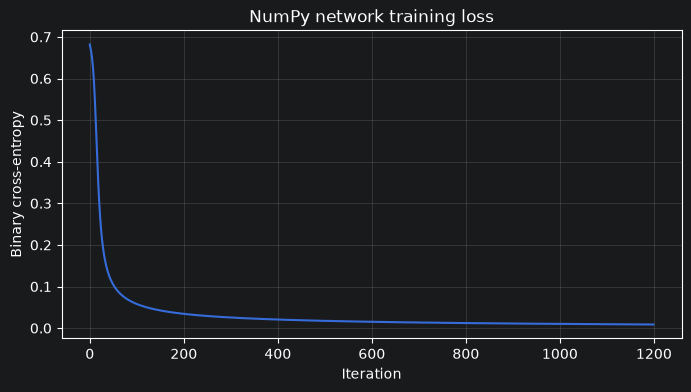

In [17]:
learning_rate = 0.5
epochs = 1200
loss_history = []

for epoch in range(epochs):
    predictions, cache = forward(X_small, W1, b1, W2, b2)
    loss_history.append(bce(y_small, predictions))
    dW1, db1, dW2, db2 = backward(X_small, y_small, W2, cache)
    W1 -= learning_rate*dW1
    b1 -= learning_rate*db1
    W2 -= learning_rate*dW2
    b2 -= learning_rate*db2

print("Initial loss:", round(loss_history[0], 4))
print("Final loss:", round(loss_history[-1], 4))
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Iteration"); plt.ylabel("Binary cross-entropy")
plt.title("NumPy network training loss")
plt.grid(alpha=0.25); plt.show()

In [18]:
final_p, _ = forward(X_small, W1, b1, W2, b2)
final_class = (final_p >= 0.5).astype(int)
print("Training accuracy (not an independent test evaluation):",
      round(np.mean(final_class == y_small), 3))

Training accuracy (not an independent test evaluation): 1.0


### 11.2 What this implementation leaves out

A production workflow should also address separate training, validation, and test sets; mini-batch training; initialization; regularization; numerical stability; reproducibility; and independent evaluation. Frameworks such as Keras automate differentiation and provide optimized operations. Understanding the mathematics helps you debug models and make informed design choices.

## 12. Connecting the mathematics to Keras

| Mathematical idea | Typical Keras concept |
|---|---|
| Affine transformation \(XW+b\) | `keras.layers.Dense` |
| Nonlinear activation | `activation="relu"` or activation layer |
| Trainable parameters | Layer weights and biases |
| Loss function | `loss=` in `compile()` |
| Gradient-based optimization | `keras.optimizers.Adam` or SGD |
| Forward pass and training loop | `model.fit()` |
| Automatic differentiation | Provided by the backend |

You normally do not calculate gradients manually when training a Keras model. The framework and backend perform automatic differentiation. This notebook explains the operations they automate.

## 13. Exercises

### A. Conceptual questions

1. What is the difference between a vector and a matrix? What does tensor rank mean?
2. A dataset contains 250 samples and 1,200 features. What is the feature matrix shape?
3. If \(X\) has shape `(32, 10)` and \(W\) has shape `(10, 4)`, what is the shape of \(XW\)?
4. Why is a Dense layer with a bias affine rather than strictly linear?
5. Why do neural networks use nonlinear activations?
6. What is the difference between a logit and a probability?
7. Why is binary cross-entropy commonly paired with a sigmoid output?
8. What does the gradient tell an optimizer?
9. What can happen if the learning rate is too high?
10. Explain backpropagation in your own words.

### B. Programming exercises

1. Create two five-element vectors and calculate their dot product.
2. Multiply matrices of shapes `(4, 3)` and `(3, 2)`. Verify the result shape.
3. Plot ReLU, sigmoid, and tanh together.
4. Implement MAE and MSE as functions.
5. Change the learning rate in the quadratic example and compare convergence.
6. Modify the NumPy network to use four hidden units.
7. Add a second hidden layer and document every tensor shape.

### C. Biological-data reasoning

1. Why might feature scaling matter when gene-expression features have different ranges?
2. Why might a model learn laboratory batch effects instead of biology?
3. Why should samples from the same patient generally remain in one partition when evaluating subject-level generalization?
4. Why does high training accuracy not establish that a gene is biologically causal?

## 14. Further exploration and references

### Core references

- Goodfellow, Bengio, and Courville, *Deep Learning*. MIT Press. See introductory material, linear algebra, numerical computation, and feed-forward networks.
- Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*.
- François Chollet, *Deep Learning with Python*.

### Online references

- [NumPy documentation](https://numpy.org/doc/stable/)
- [Keras documentation](https://keras.io/)
- [Keras Sequential model guide](https://keras.io/guides/sequential_model/)
- [Deep Learning book — online edition](https://www.deeplearningbook.org/)

Before moving on, make sure you can explain Dense-layer shapes, compute a dot product, describe the chain rule, and follow the NumPy network's forward and backward passes.

---

## Next notebook

# 03 — Keras Fundamentals and Model Building

We will move from mathematics to the Keras API: tensors, layers, Sequential and Functional models, compilation, training, evaluation, prediction, callbacks, and practical model construction.